# What does a neural network see? Classifying images with AlexNet
**Reading:** Lindsay, G. W. (2021). Convolutional neural networks as a model of the visual system: Past, present, and future. *Journal of Cognitive Neuroscience, 33*(10), 2017–2031.

**Background:** Krizhevsky, A., Sutskever, I., & Hinton, G. E. (2012). ImageNet classification with deep convolutional neural networks. *NeurIPS, 25*.

Last week you loaded AlexNet and classified a single image. AlexNet was trained on **ImageNet**: about 1.2 million photos, each labelled with one of **1,000 categories**. Today we test how far its recognition goes. 

**What you will do**
1. Look at the 1,000 labels AlexNet knows
2. See what AlexNet does with things it has **no label** for
3. Classify the five versions of each object and find out where AlexNet stops recognising them
4. Look at toys that AlexNet **does** recognise, and ask why
5. Try it with an object of your own

## Setup

In [80]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import torch
from torchvision import models, transforms
device = "cpu"

In [81]:
# Find the course data in Sciebo (works even if the shared folder was renamed)
matches = list(Path.home().glob("sciebo/*/Week3/"))
if not matches:
    raise FileNotFoundError(
        "Course data not found. Did you connect Sciebo when starting the server, "
        "and accept the shared CNU folder in Sciebo?"
    )
DATA = matches[0]
IMAGE_DIR = DATA / "images"
print(f"Using data from {DATA}")

Using data from /home/e/eilkel/sciebo/CNU/Week3


## 1. Load AlexNet

In [82]:
# Load AlexNet with its trained weights (like ResMem(pretrained=True)).
# The first time, the weights (about 230 MB) are downloaded from the internet;
# after that they are stored on your server and load quickly.
weights = models.AlexNet_Weights.IMAGENET1K_V1   # the official ImageNet-trained version
model = models.alexnet(weights=weights)

# .eval() switches off training-only behaviour (dropout), so predictions are stable
model = model.to(device).eval()

# The names of the 1,000 categories, in the order of the network's outputs
categories = weights.meta["categories"]
print(f"AlexNet knows {len(categories)} categories")

AlexNet knows 1000 categories


### Which categories does AlexNet know?
AlexNet can only answer with one of these 1,000 labels. Let's look at some of them.

In [83]:
# 20 random labels
rng = np.random.default_rng(0)        # change the number to see other labels
for i in rng.choice(len(categories), 20, replace=False):
    print(i, categories[i])

905 window shade
303 long-horned beetle
265 toy poodle
935 mashed potato
502 clog
602 horizontal bar
559 folding chair
965 burrito
625 lifeboat
643 mask
173 Ibizan hound
805 soccer ball
630 Loafer
16 bulbul
542 drumstick
74 garden spider
834 suit
500 cliff dwelling
726 plane
40 American chameleon


## 2. Load and preprocess the images
The images are prepared exactly as in Week 2: resized, cropped to the central 224 × 224 pixels, and normalised.

In [84]:
# The full preparation that goes into the network
preprocess = transforms.Compose([
    transforms.Resize(256),        # shorter side -> 256 pixels
    transforms.CenterCrop(224),    # cut out the central 224 x 224 square
    transforms.ToTensor(),         # turn the image into numbers (PyTorch's tensor format)
    transforms.Normalize(mean=[0.485, 0.456, 0.406],   # same colour normalisation
                         std=[0.229, 0.224, 0.225]),   # as in ImageNet training
])

# The same steps without the number conversion, so we can SHOW what the network sees
what_network_sees = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])

In [85]:
VERSIONS = ["imagenet", "photo", "drawing", "outline", "toy"]   # from closest to furthest from ImageNet
OBJECTS = ["zebra", "plane"]   # the objects for section 5 (panda and banana come later, in section 6)
images = {}     # images[object][version] = image, e.g. images["zebra"]["drawing"]
unknown = {}    # unknown[name] = image, e.g. unknown["giraffe"]

for path in sorted(IMAGE_DIR.iterdir()):
    if path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp"}:
        continue                                    # skip anything that is not an image
    img = Image.open(path).convert("RGB")           # RGB = 3 colour channels
    first, _, rest = path.stem.partition("_")       # "zebra_drawing" -> "zebra", "drawing"
    if first == "unknown":
        unknown[rest] = img
    elif first in OBJECTS and rest in VERSIONS:
        images.setdefault(first, {})[rest] = img
    elif rest in VERSIONS:
        continue                                    # another object, used later in section 6
    else:
        print(f"Skipped {path.name}: name should be <object>_<version>, e.g. zebra_drawing.png")

objects = list(images)
print(f"Objects: {objects}")
print(f"Unknown things: {list(unknown)}")

Objects: ['plane', 'zebra']
Unknown things: ['giraffe', 'helicopter']


## 3. Things AlexNet has no label for
None of these objects has a label among the 1,000 categories. But AlexNet **has to** answer since there is no "I don't know" option.

#### Q1. This version of AlexNet doesn't know about giraffes or helicopters, but it can "guess" what these images are. Do the guesses make sense to you? Why might AlexNet have chosen them?

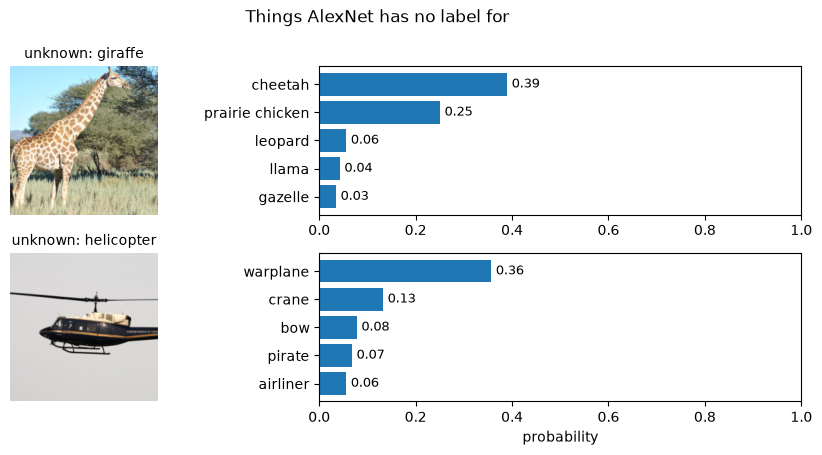

In [86]:
unknown_names = list(unknown)
unknown_imgs = [unknown[name] for name in unknown_names]
unknown_results = classify(unknown_imgs)
show_top5(unknown_imgs, [f"unknown: {n}" for n in unknown_names], unknown_results,
          title="Things AlexNet has no label for")

We set up these functions for the next section

In [87]:
def classify(imgs, k=5):
    """Return the k most likely labels and their probabilities for each image."""
    # Prepare all images and stack them into one batch
    batch = torch.stack([preprocess(img) for img in imgs]).to(device)

    # We only predict, we don't train: no gradients needed
    with torch.no_grad():
        outputs = model(batch)                    # shape: (number of images, 1000)

    # Softmax turns the 1,000 raw outputs into probabilities that sum to 1
    probs = torch.softmax(outputs, dim=1)

    # Keep the k highest probabilities and their category numbers
    top_probs, top_idx = probs.topk(k, dim=1)

    results = []
    for p_row, i_row in zip(top_probs, top_idx):
        results.append([(categories[i], p.item()) for p, i in zip(p_row, i_row)])
    return results

In [88]:
def show_top5(images, names, results, title=None):
    """One row per image: the image on the left, its top-5 predictions on the right."""
    n = len(images)
    fig, axes = plt.subplots(n, 2, figsize=(9, 2.3 * n), gridspec_kw={"width_ratios": [1, 1.7]})
    axes = np.atleast_2d(axes)
    for row, (img, name, res) in enumerate(zip(images, names, results)):
        ax_img, ax_bar = axes[row]
        ax_img.imshow(what_network_sees(img)); ax_img.axis("off")
        ax_img.set_title(name, fontsize=10)

        labels = [label for label, _ in res][::-1]   # reversed, so the top guess is on top
        probs  = [p for _, p in res][::-1]
        ax_bar.barh(labels, probs, color="tab:blue")
        ax_bar.set_xlim(0, 1)
        for y, p in enumerate(probs):
            ax_bar.text(p + 0.01, y, f"{p:.2f}", va="center", fontsize=9)
    axes[-1, 1].set_xlabel("probability")
    if title:
        fig.suptitle(title)
    plt.tight_layout(); plt.show()

## 4. The five versions of zebras

| Version | What it is |
|---|---|
| `imagenet` | a photo from ImageNet |
| `photo` | a new photo of the same kind of object, not from ImageNet |
| `drawing` | a coloured drawing of the object |
| `outline` | a black-and-white line drawing of the object |
| `toy` | a toy version of the object |

#### Q2. Can AlexNet recognise all versions as the right concept? Look at the wrong classifications: do they **look** like the object (shape, colour, texture), or do they **mean** something similar?

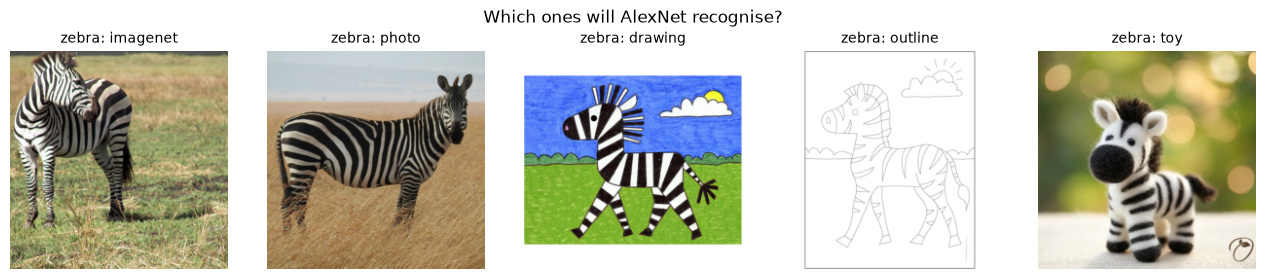

In [75]:
# One row per version of the zebra
SHOW = ["zebra"]
fig, axes = plt.subplots(len(SHOW), len(VERSIONS),
                         figsize=(2.6 * len(VERSIONS), 2.8 * len(SHOW)), squeeze=False)
for row, obj in enumerate(SHOW):
    for col, version in enumerate(VERSIONS):
        ax = axes[row, col]
        ax.axis("off")
        if version in images[obj]:
            ax.imshow(what_network_sees(images[obj][version]))
            ax.set_title(f"{obj}: {version}", fontsize=10)
fig.suptitle("Which ones will AlexNet recognise?")
plt.tight_layout(); plt.show()

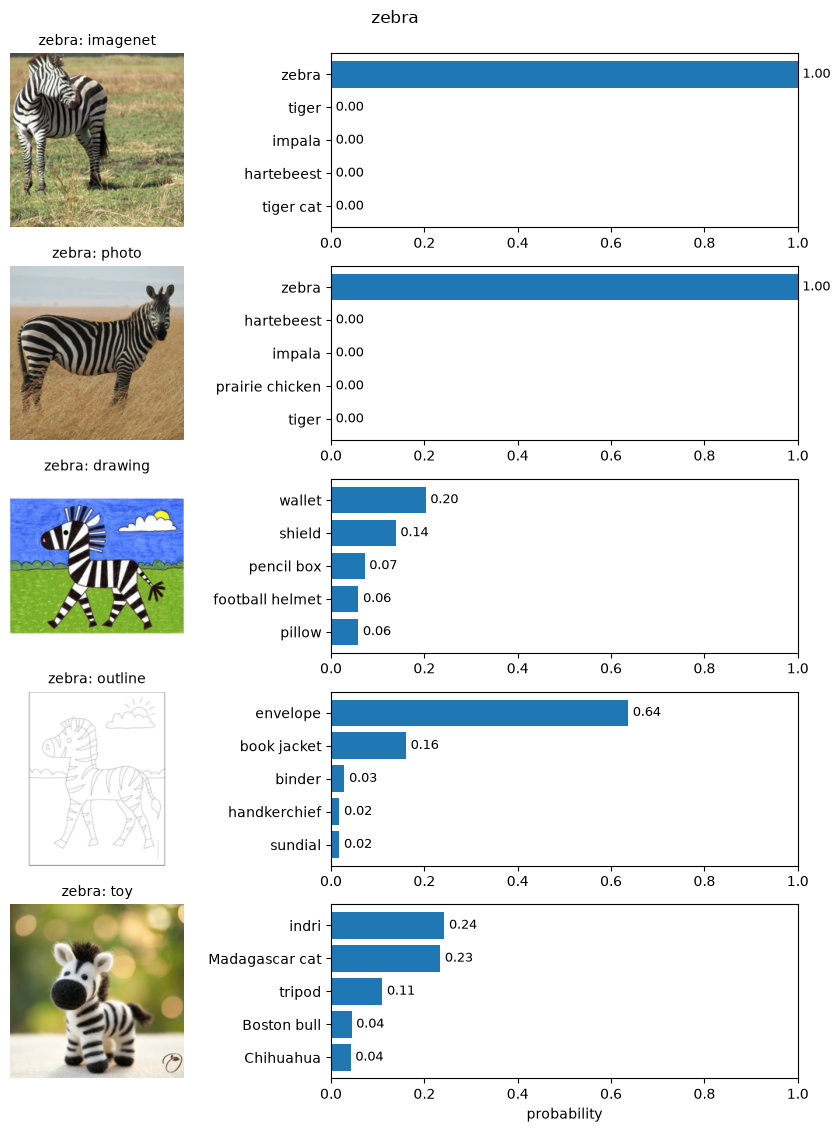

In [76]:
# Classify every version of every object and show the top-5
results = {}    # results[object][version] = top-5 list
for obj in SHOW:
    versions = [v for v in VERSIONS if v in images[obj]]
    imgs = [images[obj][v] for v in versions]
    res = classify(imgs)
    results[obj] = dict(zip(versions, res))
    show_top5(imgs, [f"{obj}: {v}" for v in versions], res, title=obj)

## 6. When toys *do* work

### Q3. AlexNet recognised some toys but not others. Compare the toys it recognised with their real versions: what do they have in common (colour, pattern, texture, shape)? Thinking back to Q2, what do these results tell you about which features of an image AlexNet relies on?

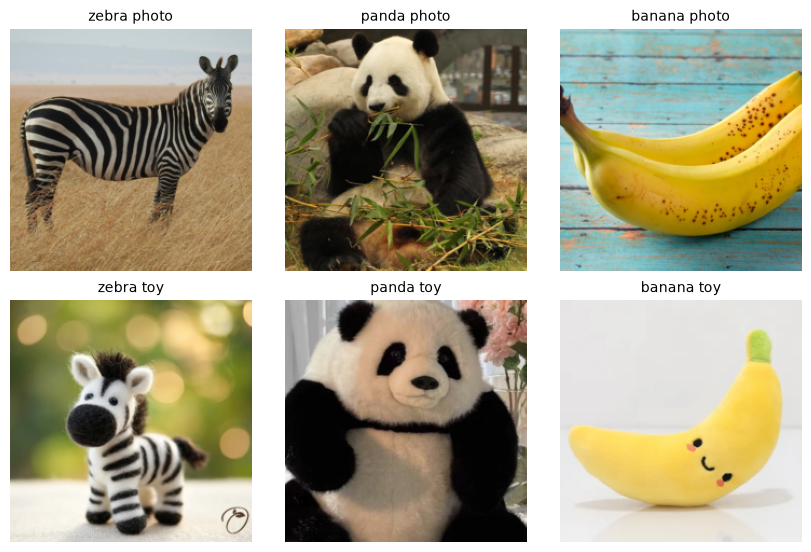

In [89]:
TOY_DIR = IMAGE_DIR
# object name in the file names -> the ImageNet label that counts as correct
TOY_OBJECTS = {"zebra": "zebra", "panda": "giant panda", "banana": "banana"}

toy_names, toy_imgs = [], []
for obj in TOY_OBJECTS:
    for version in ["photo", "toy"]:
        path = next(TOY_DIR.glob(f"{obj}_{version}.*"))      # e.g. panda_toy.jpg
        toy_names.append(f"{obj} {version}")
        toy_imgs.append(Image.open(path).convert("RGB"))

fig, axes = plt.subplots(2, len(TOY_OBJECTS), figsize=(2.8 * len(TOY_OBJECTS), 5.6))
for k, (name, img) in enumerate(zip(toy_names, toy_imgs)):
    ax = axes[k % 2, k // 2]                                 # photos on top, toys below
    ax.imshow(what_network_sees(img)); ax.set_title(name, fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

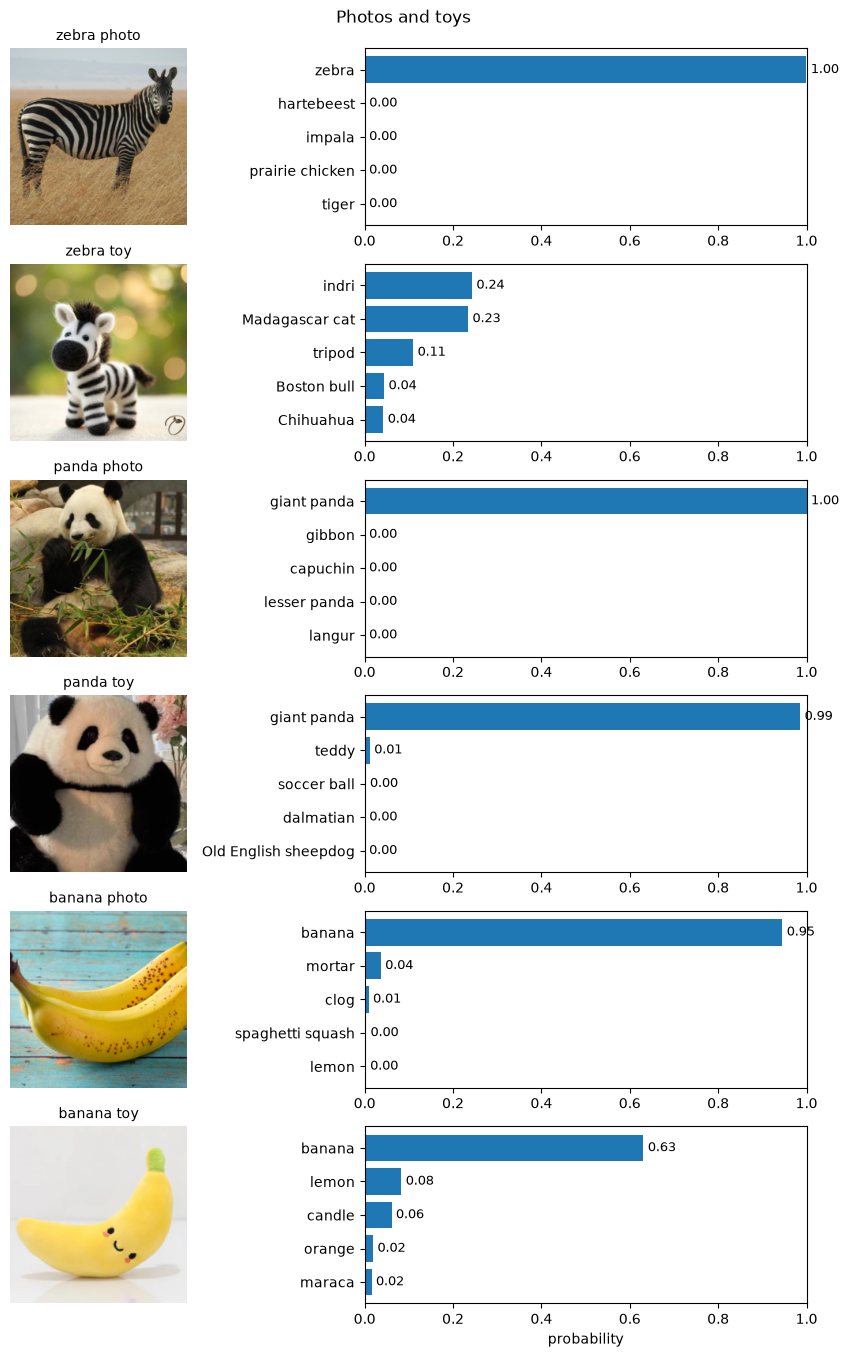

In [90]:
toy_results = classify(toy_imgs)
show_top5(toy_imgs, toy_names, toy_results, title="Photos and toys")

## 7. Explore: your own object (OPTIONAL)
Pick an object that is one of AlexNet's 1,000 labels. To check, search the label list, e.g. for cups:
`[c for c in categories if "cup" in c]`

Then find a **photo**, a **drawing** and a **toy** version of it online.

1. In the file browser on the left, create a folder called `my_images`.
2. Upload your images into it and name them like the course images: `<object>_<version>`, e.g. `cup_photo.jpg`, `cup_drawing.png`, `cup_toy.jpg`.
3. Run the cells below.

In [91]:
def pad_to_square(img, fill="white"):
    """Put the image on a white square, with enough margin that the centre crop
    only removes white space. This way nothing of the object is cut off."""
    w, h = img.size
    size = round(max(w, h) * 256 / 224) + 4         # the crop keeps 224 of 256 pixels
    square = Image.new("RGB", (size, size), fill)
    square.paste(img, ((size - w) // 2, (size - h) // 2))   # paste the image in the centre
    return square

MY_DIR = Path("my_images")
my_images = {}  # my_images[object][version] = image
if not MY_DIR.exists():
    print('Create a folder "my_images" and upload your images first (see the steps above).')

for path in (sorted(MY_DIR.iterdir()) if MY_DIR.exists() else []):
    if path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp"}:
        continue
    obj, _, version = path.stem.partition("_")
    if version not in VERSIONS:
        print(f"Skipped {path.name}: name should be <object>_<version>, e.g. cup_drawing.png")
        continue
    img = pad_to_square(Image.open(path).convert("RGB"))
    my_images.setdefault(obj, {})[version] = img

print(f"Your objects: {list(my_images)}")

Create a folder "my_images" and upload your images first (see the steps above).
Your objects: []


In [92]:
for obj in my_images:
    versions = [v for v in VERSIONS if v in my_images[obj]]
    imgs = [my_images[obj][v] for v in versions]
    show_top5(imgs, [f"{obj}: {v}" for v in versions], classify(imgs), title=f"Your object: {obj}")